In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 

In [3]:
t = np.array([0, 1, 2, 3, 4])
N_high = np.array([1000, 500, 250, 125, 62])
N_low = np.array([5, 2, 1, 1, 1])


In [4]:
df = pd.DataFrame({
    'time' : t,
    'High_statistics beam' : N_high,  
    'Low_statistics beam' : N_low  
})

In [5]:
df 

,time,High_statistics beam,Low_statistics beam
0,0,1000,5
1,1,500,2
2,2,250,1
3,3,125,1
4,4,62,1


In [7]:
from sklearn.linear_model import LinearRegression

In [8]:
cols = ["High_statistics beam", "Low_statistics beam"]

df[[f"log_{col}" for col in cols]] = np.log(df[cols])

In [9]:
df 

,time,High_statistics beam,Low_statistics beam,log_High_statistics beam,log_Low_statistics beam
0,0,1000,5,6.907755,1.609438
1,1,500,2,6.214608,0.693147
2,2,250,1,5.521461,0.000000
3,3,125,1,4.828314,0.000000
4,4,62,1,4.127134,0.000000


In [10]:
x = df[['time']]
y1 = df['log_High_statistics beam']
y2 = df['log_Low_statistics beam']


In [11]:
model1 = LinearRegression() 
model2 = LinearRegression() 
model1.fit(x, y1) 
model2.fit(x, y2) 


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.39]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['time']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.243
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [12]:
c1 = model1.intercept_
m1 = model1.coef_

c2 = model2.intercept_ 
m2 = model2.coef_ 

Intercept (c): 6.90936171332159
Coefficient (m): -0.6947536148993981


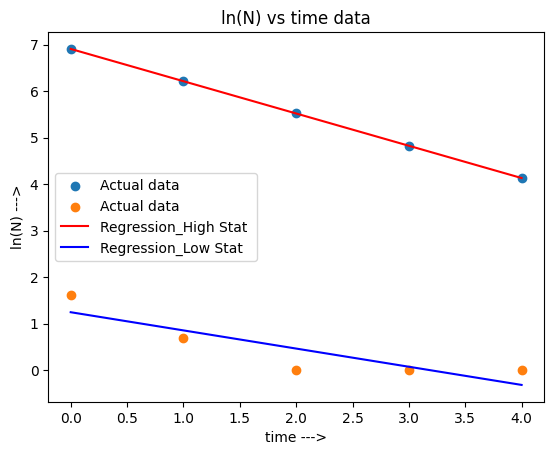

In [17]:
t_line = np.linspace(df["time"].min(), df["time"].max(), 100)

lnn_line1 = m1*t_line + c1
lnn_line2 = m2*t_line + c2 

plt.scatter(df["time"], df["log_High_statistics beam"], label = "Actual data")
plt.scatter(df["time"], df["log_Low_statistics beam"], label = "Actual data")

plt.plot(t_line, lnn_line1, color = "red", label = "Regression_High Stat ")
plt.plot(t_line, lnn_line2, color = "blue", label = "Regression_Low Stat ")

plt.title("ln(N) vs time data")
plt.xlabel('time --->')
plt.ylabel('ln(N) --->')
plt.legend()
plt.show()